# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é que vocês apliquem os conceitos estatísticos vistos no último módulo, mais os conceitos de visualizações de dados através de gráficos e finalizem publicando no seu github!

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px



Faça a leitura dos dados do arquivo CSV:


Altere o código abaixo de acordo com seu diretório.

In [2]:
df = pd.read_csv('base_supermercado.csv')

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


Os campos do nosso dataframe são:

**Title:** Nome do produto.


**Marca:** A marca do produto.


**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.


**Preco_Desconto:** O preço vendido após o desconto ser aplicado.


**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.


**Desconto:** Total de desconto aplicado.






As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.


As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [3]:
#Seu código aqui para a média
media = df.groupby('Categoria')['Preco_Normal'].mean()
media

Categoria
belleza-y-cuidado-personal    1783.556485
comidas-preparadas            3095.043478
congelados                    2108.042553
frutas                        1724.473684
instantaneos-y-sopas           765.491228
lacteos                       2385.219239
verduras                      1343.296875
Name: Preco_Normal, dtype: float64

In [4]:
#Seu código aqui para a mediana
mediana = df.groupby('Categoria')['Preco_Normal'].median()
mediana

Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64

In [5]:
# Comparando as duas lado a lado
comparacao = pd.DataFrame({'media': media, 'mediana': mediana})
comparacao['media_acima_da_mediana'] = comparacao['media'] > comparacao['mediana']
comparacao.round(1)

,media,mediana,media_acima_da_mediana
Categoria,,,
belleza-y-cuidado-personal,1783.6,1569.0,True
comidas-preparadas,3095.0,3290.0,False
congelados,2108.0,1519.0,True
frutas,1724.5,1195.0,True
instantaneos-y-sopas,765.5,439.0,True
lacteos,2385.2,989.0,True
verduras,1343.3,1180.0,True


Digite aqui as categorias:
Análise de Distribuição de Preços por Categoria
A comparação entre a média e a mediana dos preços revela assimetrias importantes no comportamento de diferentes categorias:
Categorias com média superior à mediana (6 no total): Composta por lacteos, instantaneos-y-sopas, frutas, congelados, belleza-y-cuidado-personal e verduras. Esse cenário demonstra a presença de itens com valores substancialmente elevados que elevam a média geral. A disparidade é especialmente marcante em lacteos (média de 2385,2 contra mediana de 989,0) e em instantaneos-y-sopas (média de 765,5 contra mediana de 439,0).
Categoria com média inferior à mediana (1 no total): Identificada em comidas-preparadas (média de 3095,0 contra mediana de 3290,0), indicando que produtos de menor custo estão reduzindo a média da categoria.


# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [6]:
#Seu código aqui
desvio = df.groupby('Categoria')['Preco_Normal'].std()
desvio.sort_values(ascending=False)


Categoria
lacteos                       3925.816164
belleza-y-cuidado-personal    2210.041719
congelados                    2111.539896
comidas-preparadas            2019.911428
frutas                        1639.151114
instantaneos-y-sopas          1170.232869
verduras                      1012.699625
Name: Preco_Normal, dtype: float64

In [7]:
resumo = pd.DataFrame({'media': media, 'mediana': mediana, 'desvio_padrao': desvio})
resumo.sort_values('desvio_padrao', ascending=False).round(1)

,media,mediana,desvio_padrao
Categoria,,,
lacteos,2385.2,989.0,3925.8
belleza-y-cuidado-personal,1783.6,1569.0,2210.0
congelados,2108.0,1519.0,2111.5
comidas-preparadas,3095.0,3290.0,2019.9
frutas,1724.5,1195.0,1639.2
instantaneos-y-sopas,765.5,439.0,1170.2
verduras,1343.3,1180.0,1012.7


Digite nesse campo o comportamento que você identificou.

A categoria com maior desvio padrão é lacteos (3925,8), seguida de belleza-y-cuidado-personal (2210,0) e congelados (2111,5). Nessas categorias a média fica acima da mediana, e a diferença aumenta com o desvio. Em lacteos a média (2385,2) é mais que o dobro da mediana (989,0), e o desvio é maior que a própria média. Isso indica uma distribuição assimétrica: a maioria dos produtos tem preço baixo, mas poucos produtos de preço muito alto puxam a média para cima e aumentam a dispersão.

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

Dica: Para trazer apenas os dados da categoria que você deseja você pode usar o df.loc[df['Categoria'] == 'CATEGORIA ESCOLHIDA'

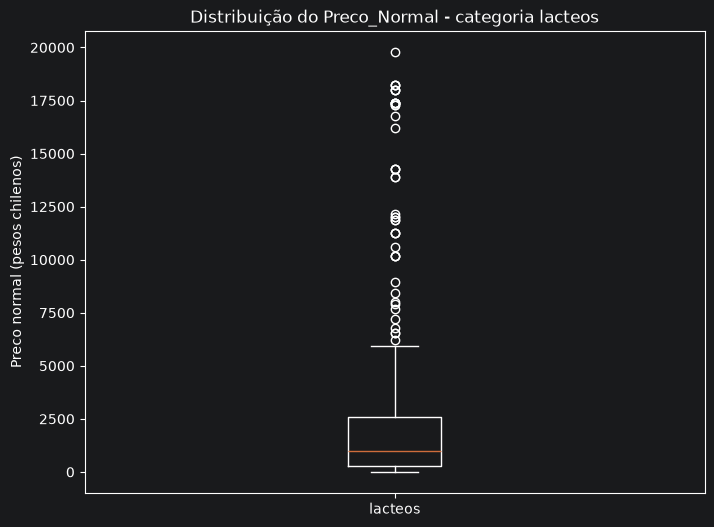

In [8]:
#Seu código aqui
lacteos = df.loc[df['Categoria'] == 'lacteos', 'Preco_Normal']
lacteos.describe()

plt.figure(figsize=(8,6))
plt.boxplot(lacteos)
plt.title('Distribuição do Preco_Normal - categoria lacteos')
plt.ylabel('Preco normal (pesos chilenos)')
plt.xticks([1], ['lacteos'])
plt.savefig('boxplot_lacteos.png', dpi=150, bbox_inches='tight')
plt.show()

In [9]:
q1 = lacteos.quantile(0.25)
q3 = lacteos.quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr
print(f'Q1={q1}, Q3={q3}, IQR={iqr}')
print(f'Limites: {limite_inferior} a {limite_superior}')

outliers = df.loc[
    (df['Categoria'] == 'lacteos') &
    ((df['Preco_Normal'] > limite_superior) | (df['Preco_Normal'] < limite_inferior)),
    ['title', 'Marca', 'Preco_Normal']
].sort_values('Preco_Normal', ascending=False)

print(f'Quantidade de outliers: {len(outliers)}')
outliers

Q1=269.0, Q3=2609.0, IQR=2340.0
Limites: -3241.0 a 6119.0
Quantidade de outliers: 43


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


In [10]:
# O que foi observado durante a analise do boxplot:
#Distribuição: o boxplot de lácteos mostra uma distribuição assimétrica, com cauda longa à direita. A caixa é achatada (Q1 = 269 e Q3 = 2.609), e a mediana (989) fica mais próxima da parte baixa da caixa. Isso mostra que a maioria dos produtos tem preço baixo.

#Outliers: Sim, há muitos: são 43 produtos (cerca de 9,6% dos 447), todos acima do limite superior de 6.119 (Q3 + 1,5 × IQR). Não há outliers inferiores, porque o limite inferior é negativo. São quase todos packs com 12 unidades de leite de 1 L e embalagens grandes de leite em pó (Nido, Svelty e Colun), com preços de 6.229 a 19.788. Não parecem erros de dado, e sim produtos vendidos em grande quantidade. São esses valores que puxam a média (2.385) para cima da mediana.

#Observação sobre a base: 294 dos 1.107 produtos (26,6%) têm Preco_Normal = 0, sendo 95 em lácteos. Isso indica que o preço normal não foi registrado. Como esses valores zerados entraram nos cálculos, eles reduzem o Q1 e a mediana.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

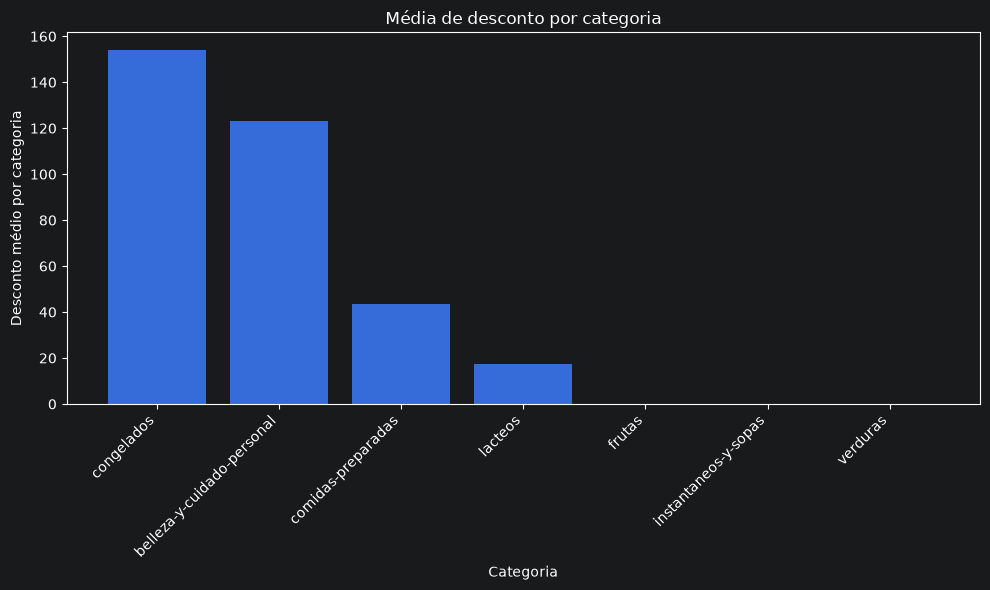

In [11]:
# Seu código aqui

media_desconto = df.groupby('Categoria')['Desconto'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
plt.bar(media_desconto.index, media_desconto.values)
plt.title('Média de desconto por categoria')
plt.xlabel('Categoria')
plt.ylabel('Desconto médio por categoria')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('barras_desconto_categoria.png', dpi=150, bbox_inches='tight')
plt.show()

In [12]:
#Analise do gráfico:
#congelados tem a maior média de desconto, cerca de 154. Depois vêm belleza-y-cuidado-personal, com aproximadamente 123; comidas-preparadas, com 43; e lacteos, com 17. Já frutas, instantaneos-y-sopas e verduras têm média zero, porque nenhum produto dessas categorias tem desconto. A média inclui todos os produtos, mesmo os sem desconto. Como apenas 118 dos 1.107 produtos estão com desconto, ela mostra a prática geral de cada categoria, e não o valor de um desconto específico.




# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [15]:
# Seu código aqui

agrupado = df.groupby(['Categoria', 'Marca']).agg(
    desconto_medio = ('Desconto' , 'mean'),
    qtd_produtos = ('title', 'count')
).reset_index()

fig = px.treemap(
    agrupado,
    path =['Categoria', 'Marca'],
    values ='qtd_produtos',
    color ='desconto_medio',
    color_continuous_scale ='RdYlGn_r',
    title = 'Média de desconto por categoria e marca'
)
fig.update_traces(
    hovertemplate='%{label}<br>Produtos: %{value}<br>Desconto médio: %{color:.1f}<extra></extra>'
)
fig.show(renderer='browser')
fig.write_html('mapa_desconto.html')

In [14]:
#Leitura do mapa
#No mapa, o tamanho de cada retângulo indica a quantidade de produtos, e a cor mostra a média de desconto: verde-escuro representa zero e vermelho, os maiores descontos.

#lacteos é a categoria com mais produtos, mas aparece quase toda em verde-escuro, indicando que a maioria das marcas não tem descontos. As exceções incluem Nido, com média de 869,8, e Sureña, com 261,0.

#Em congelados e belleza-y-cuidado-personal, há mais marcas em tons de amarelo, laranja e vermelho. Em congelados, destacam-se Magnum (955,0) e Savory (456,2). Em belleza-y-cuidado-personal, aparecem Pantene (684,9), BiO (650,0) e Dove (429,9).

#Já frutas, verduras e instantaneos-y-sopas ficam totalmente verdes, pois nenhum produto dessas categorias tem desconto. No total, apenas 43 das 167 combinações de categoria e marca têm média de desconto acima de zero.

#As marcas com as maiores médias costumam ter poucos produtos — Magnum tem 4 e Nido, 5 —, então esses valores podem não representar muito bem o conjunto de cada marca.